In [2]:
# Healthcare Risk Prediction Using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    roc_auc_score
)

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"D:\MCA_Major_Project\datasets")

diabetes = pd.read_csv(DATA_DIR / "diabetes.csv")
hypertension = pd.read_csv(DATA_DIR / "hypertension_dataset.csv")
mental_health = pd.read_csv(DATA_DIR / "Mental Health Dataset.csv")

print("Diabetes dataset:", diabetes.shape)
print("Hypertension dataset:", hypertension.shape)
print("Mental health dataset:", mental_health.shape)

print("\nDiabetes columns:")
print(diabetes.columns.tolist())

print("\nHypertension columns:")
print(hypertension.columns.tolist())

print("\nMental health columns:")
print(mental_health.columns.tolist())

Diabetes dataset: (768, 9)
Hypertension dataset: (174982, 23)
Mental health dataset: (292364, 17)

Diabetes columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Hypertension columns:
['Country', 'Age', 'BMI', 'Cholesterol', 'Systolic_BP', 'Diastolic_BP', 'Smoking_Status', 'Alcohol_Intake', 'Physical_Activity_Level', 'Family_History', 'Diabetes', 'Stress_Level', 'Salt_Intake', 'Sleep_Duration', 'Heart_Rate', 'LDL', 'HDL', 'Triglycerides', 'Glucose', 'Gender', 'Education_Level', 'Employment_Status', 'Hypertension']

Mental health columns:
['Timestamp', 'Gender', 'Country', 'Occupation', 'self_employed', 'family_history', 'treatment', 'Days_Indoors', 'Growing_Stress', 'Changes_Habits', 'Mental_Health_History', 'Mood_Swings', 'Coping_Struggles', 'Work_Interest', 'Social_Weakness', 'mental_health_interview', 'care_options']


In [4]:
datasets = {
    "Diabetes": (diabetes, "Outcome"),
    "Hypertension": (hypertension, "Hypertension"),
    "Mental Health": (mental_health, "treatment")
}

for name, (df, target) in datasets.items():
    print(f"\n{'=' * 45}")
    print(f"{name} Dataset")
    print(f"{'=' * 45}")

    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("\nTarget distribution:")
    print(df[target].value_counts(dropna=False))


Diabetes Dataset
Rows and columns: (768, 9)
Missing values: 0

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Hypertension Dataset
Rows and columns: (174982, 23)
Missing values: 0

Target distribution:
Hypertension
High    125781
Low      49201
Name: count, dtype: int64

Mental Health Dataset
Rows and columns: (292364, 17)
Missing values: 5202

Target distribution:
treatment
Yes    147606
No     144758
Name: count, dtype: int64


In [10]:

# ============================================================
# HEALTHCARE RISK PREDICTION
# PAPER-ALIGNED REGRESSION EXPERIMENT
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
MAX_ROWS = 5000

# Each dataset is analyzed independently.
# Positive indicators are explicitly defined.
dataset_config = {
    "Diabetes": {
        "data": diabetes,
        "target": "Outcome",
        "positive": "1"
    },
    "Hypertension": {
        "data": hypertension,
        "target": "Hypertension",
        "positive": "high"
    },
    "Mental Health": {
        "data": mental_health,
        "target": "treatment",
        "positive": "yes"
    }
}

# ------------------------------------------------------------
# DEFINE THE FIVE REGRESSION MODELS IN THE PAPER
# ------------------------------------------------------------

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "Support Vector Regressor": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    )
}

try:
    from xgboost import XGBRegressor

    models["XGBoost Regressor"] = XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
except ImportError:
    raise ImportError(
        "XGBoost is required by the paper. "
        "Install it using: pip install xgboost"
    )


# ------------------------------------------------------------
# PREPROCESSING FUNCTION
# ------------------------------------------------------------

def build_preprocessor(X):
    numeric_columns = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_columns = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    numeric_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Dense output is needed for PCA.
    try:
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        # Compatibility with older scikit-learn versions.
        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    categorical_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])

    transformers = []

    if numeric_columns:
        transformers.append(
            ("numeric", numeric_pipeline, numeric_columns)
        )

    if categorical_columns:
        transformers.append(
            ("categorical", categorical_pipeline, categorical_columns)
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


# ------------------------------------------------------------
# PREPARE EACH DATASET AND TRAIN THE MODELS
# ------------------------------------------------------------

experiment_results = {}
all_result_rows = []

for dataset_name, config in dataset_config.items():

    df = config["data"].copy()
    target = config["target"]
    positive_label = config["positive"]

    # Remove rows with missing target values.
    df = df.dropna(subset=[target]).copy()

    # Keep a reproducible sample to control memory and runtime.
    if len(df) > MAX_ROWS:
        df = df.sample(
            n=MAX_ROWS,
            random_state=RANDOM_STATE
        ).copy()

    X = df.drop(columns=[target]).copy()

    # Remove likely identifier columns from model inputs.
    id_columns = [
        col for col in X.columns
        if col.strip().lower() in {
            "id", "patient_id", "patientid", "record_id"
        }
    ]
    X = X.drop(columns=id_columns, errors="ignore")

    # Explicitly encode the positive health indicator as 1.
    target_strings = df[target].astype(str).str.strip().str.lower()

    if target_strings.nunique() != 2:
        raise ValueError(
            f"{dataset_name}: expected exactly two target classes, "
            f"found {target_strings.unique().tolist()}. "
            "Check the target encoding before continuing."
        )

    if positive_label not in set(target_strings):
        raise ValueError(
            f"{dataset_name}: positive label '{positive_label}' "
            f"not found in {target_strings.unique().tolist()}."
        )

    y = (target_strings == positive_label).astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    preprocessor = build_preprocessor(X_train)

    # Use SMOTE only on the training data.
    # With binary encoded targets, this is a proxy regression setup,
    # not standard continuous-target regression oversampling.
    class_counts = y_train.value_counts()
    use_smote = class_counts.min() >= 4

    fitted_models = {}
    prediction_store = {}

    for model_name, model in models.items():

        steps = [
            ("preprocessing", preprocessor),
            ("pca", PCA(n_components=0.95, svd_solver="full"))
        ]

        if use_smote:
            steps.append((
                "smote",
                SMOTE(
                    random_state=RANDOM_STATE,
                    k_neighbors=min(3, int(class_counts.min()) - 1)
                )
            ))

        steps.append(("regressor", model))

        pipeline = Pipeline(steps)

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, predictions)

        all_result_rows.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse,
            "R2 Score": r2
        })

        fitted_models[model_name] = pipeline
        prediction_store[model_name] = predictions

    dataset_results = pd.DataFrame([
        row for row in all_result_rows
        if row["Dataset"] == dataset_name
    ])

    # Highest R2 is the selection criterion.
    best_model_name = dataset_results.loc[
        dataset_results["R2 Score"].idxmax(),
        "Model"
    ]

    experiment_results[dataset_name] = {
        "models": fitted_models,
        "predictions": prediction_store,
        "X_test": X_test,
        "y_test": y_test,
        "best_model_name": best_model_name,
        "best_model": fitted_models[best_model_name],
        "positive_label": positive_label
    }

# Results table for Cell 8.
all_results = pd.DataFrame(all_result_rows)

all_results = all_results.sort_values(
    ["Dataset", "R2 Score"],
    ascending=[True, False]
).reset_index(drop=True)

display(all_results.round(4))


,Dataset,Model,MAE,MSE,RMSE,R2 Score
0,Diabetes,Gradient Boosting Regressor,0.3321,0.1719,0.4146,0.2452
1,Diabetes,Random Forest Regressor,0.3231,0.1744,0.4176,0.2340
2,Diabetes,Linear Regression,0.3634,0.1838,0.4287,0.1927
3,Diabetes,XGBoost Regressor,0.3353,0.1850,0.4301,0.1877
4,Diabetes,Support Vector Regressor,0.3429,0.2039,0.4515,0.1045
5,Hypertension,Random Forest Regressor,0.4409,0.2189,0.4678,-0.0928
6,Hypertension,XGBoost Regressor,0.4761,0.2387,0.4886,-0.1920
7,Hypertension,Gradient Boosting Regressor,0.4852,0.2432,0.4931,-0.2142
8,Hypertension,Support Vector Regressor,0.4221,0.2512,0.5012,-0.2545
9,Hypertension,Linear Regression,0.4996,0.2526,0.5025,-0.2611


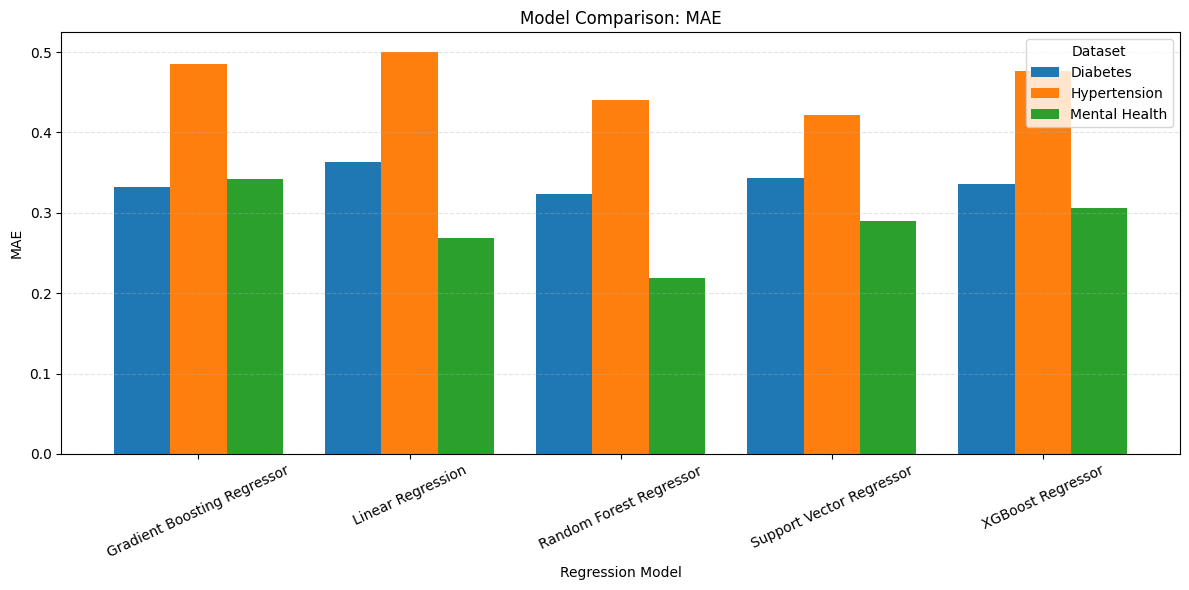

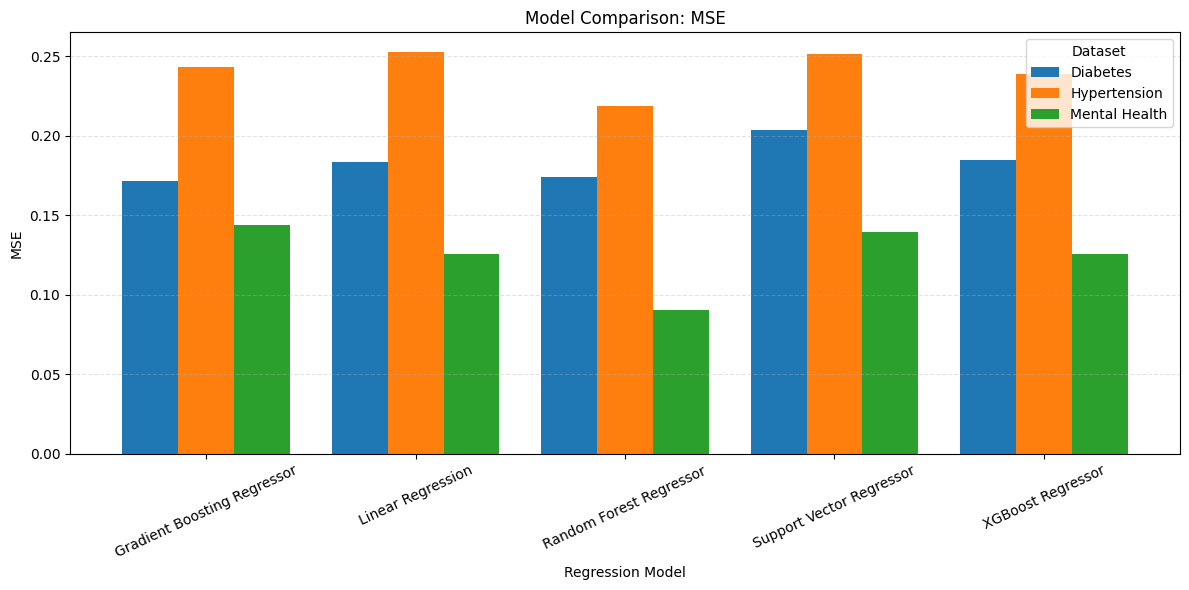

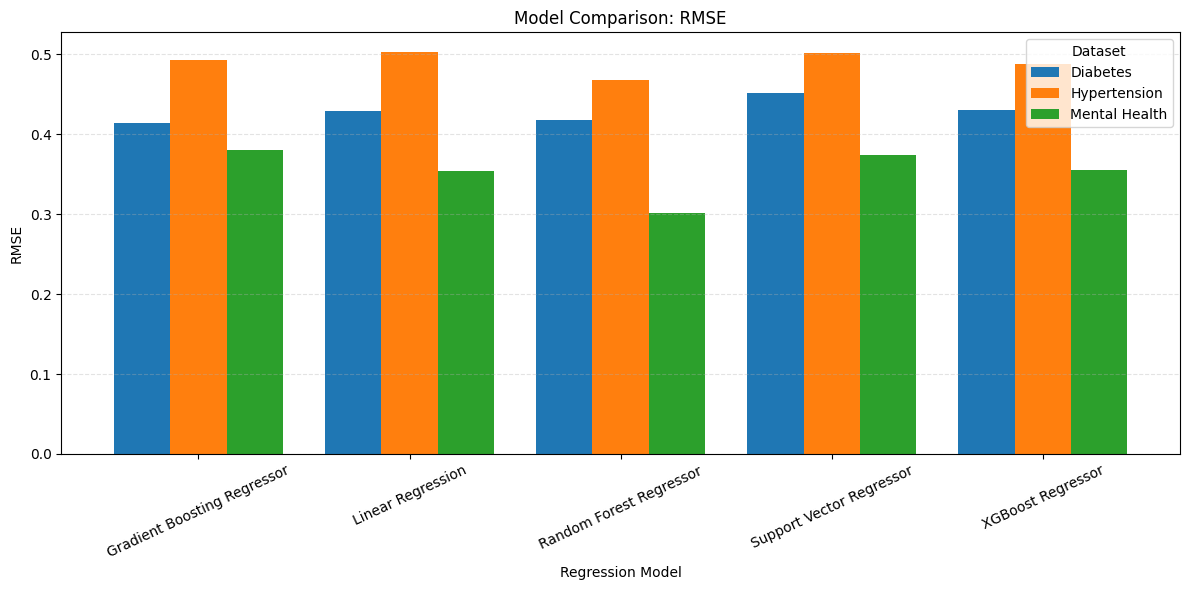

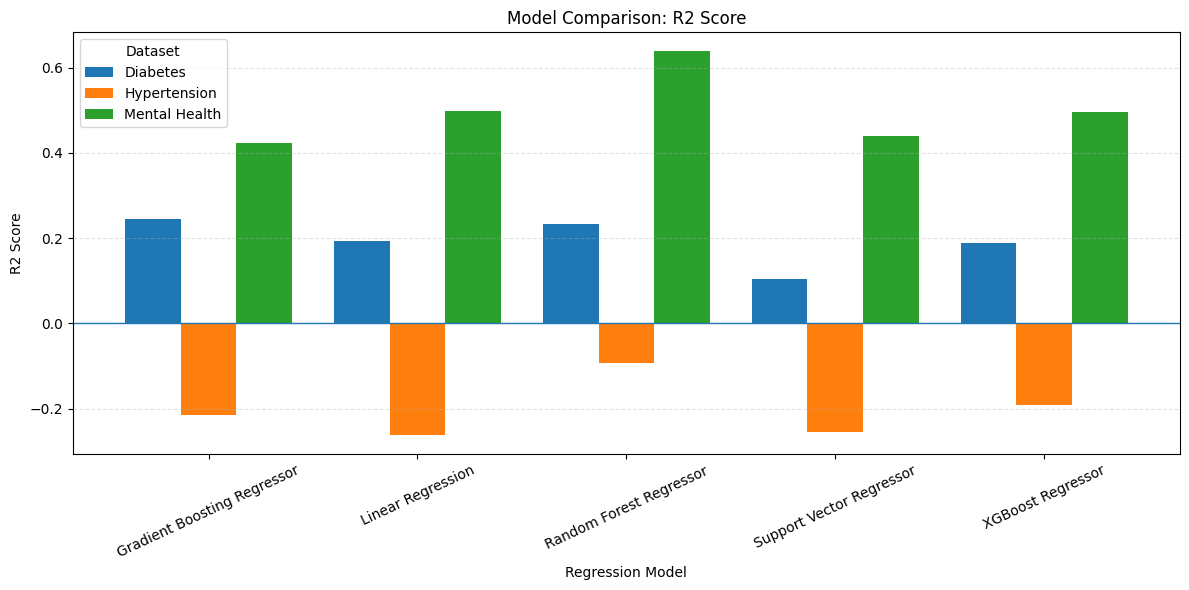

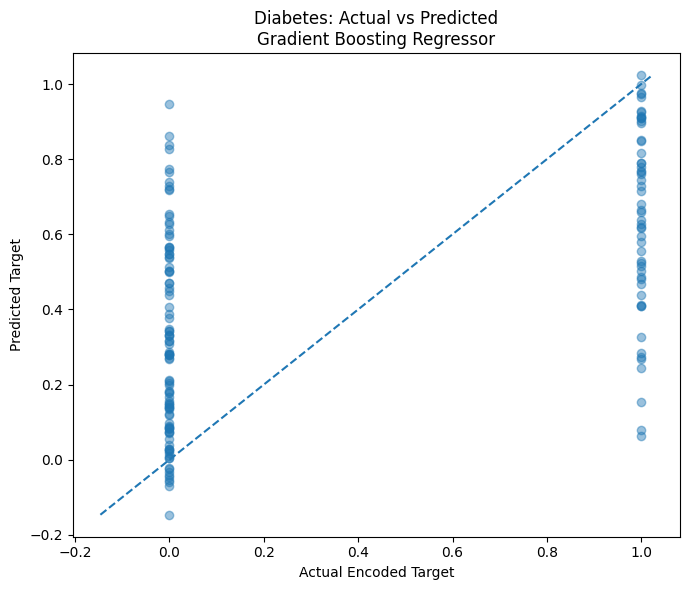

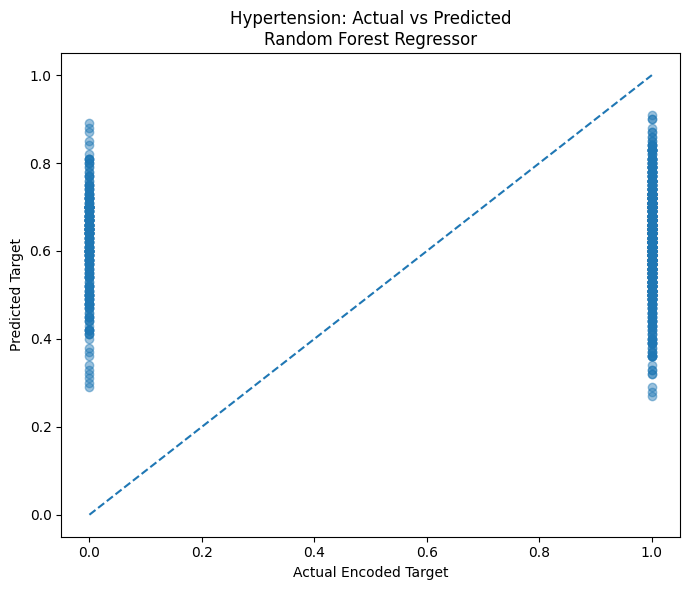

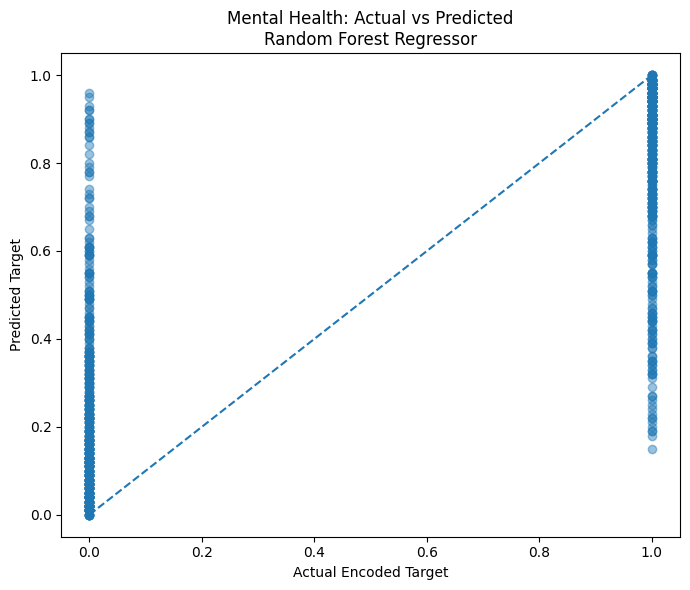

ValueError: X has 7 features, but GradientBoostingRegressor is expecting 288 features as input.

In [ ]:

# ============================================================
# CELL 8: PAPER-ALIGNED REGRESSION VISUALIZATIONS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Validate the results before plotting.
required_columns = {
    "Dataset", "Model", "MAE", "MSE", "RMSE", "R2 Score"
}

if "all_results" not in globals():
    raise NameError("Run the model-training cell before Cell 8.")

if not required_columns.issubset(all_results.columns):
    raise ValueError(
        "The results table does not contain the required regression metrics."
    )

results = all_results.copy()

# ------------------------------------------------------------
# 1. OVERALL MODEL PERFORMANCE
# ------------------------------------------------------------

metric_columns = ["MAE", "MSE", "RMSE", "R2 Score"]

for metric in metric_columns:

    chart_data = results.pivot_table(
        index="Model",
        columns="Dataset",
        values=metric,
        aggfunc="mean"
    )

    ax = chart_data.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title(f"Model Comparison: {metric}")
    ax.set_xlabel("Regression Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

    if metric == "R2 Score":
        ax.axhline(0, linewidth=1)

    ax.legend(title="Dataset")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 2. ACTUAL VS PREDICTED VALUES FOR EACH DATASET
# ------------------------------------------------------------

for dataset_name, result in experiment_results.items():

    best_name = result["best_model_name"]
    actual = np.asarray(result["y_test"])
    predicted = np.asarray(result["predictions"][best_name])

    plt.figure(figsize=(7, 6))
    plt.scatter(actual, predicted, alpha=0.45)

    # Reference line for perfect predictions.
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    plt.title(
        f"{dataset_name}: Actual vs Predicted\n"
        f"{best_name}"
    )
    plt.xlabel("Actual Encoded Target")
    plt.ylabel("Predicted Target")
    plt.tight_layout()
    plt.show()


# 
# ------------------------------------------------------------
# 3. FEATURE IMPORTANCE USING PERMUTATION IMPORTANCE
# ------------------------------------------------------------

from sklearn.inspection import permutation_importance

for dataset_name, result in experiment_results.items():

    best_name = result["best_model_name"]
    best_model = result["best_model"]

    X_test = result["X_test"]
    y_test = result["y_test"]

    # Use a small sample to reduce execution time.
    sample_count = min(200, len(X_test))
    X_explain = X_test.iloc[:sample_count].copy()
    y_explain = y_test.iloc[:sample_count].copy()

    # Calculate importance on the original input features.
    # The complete fitted pipeline handles preprocessing and PCA.
    importance = permutation_importance(
        estimator=best_model,
        X=X_explain,
        y=y_explain,
        scoring="r2",
        n_repeats=2,
        random_state=42,
        n_jobs=1
    )

    importance_df = pd.DataFrame({
        "Feature": X_explain.columns,
        "Importance": importance.importances_mean
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).head(15)

    importance_df = importance_df.sort_values("Importance")

    plt.figure(figsize=(9, 6))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    plt.title(f"{dataset_name}: Top 15 Feature Importance")
    plt.xlabel("Decrease in R² after feature permutation")
    plt.ylabel("Original Feature")
    plt.tight_layout()
    plt.show()
